# Preprocessing data in MNE-Python

`
Authors:
Marijn van Vliet, Britta Westner, Alexandre Gramfort, Denis A. Engemann
`

In this session we go from raw data to clean epochs.

In [1]:
# This makes figures appear inside the notebook instead of in a new window.
%matplotlib inline

# We set the log-level of MNE-Python to 'warning' so the output is less verbose:
import mne
mne.set_log_level('error')

# Disable all warnings so they don't end up in the HTML.
import warnings
warnings.filterwarnings("ignore")

# Specify rendering backends
mne.viz.set_browser_backend("qt")

## Setup

We start out with loading the packages we need. These include `matplotlib` for plotting, `os` for path management, `numpy` for numerical computations, and of course `mne`.
We also use matplotlib magic to ask for figure to be plotted inline. 

In [2]:
# These are the Python packages we will use in this session.
import numpy as np  # for numerical computations
import matplotlib.pyplot as plt  # for making custom figures
import mne  # for MEG and EEG data analysis

Let's double check your MNE-Python version. This should give back `1.13` or higher.

In [3]:
mne.__version__

'1.13.2'

```{note}

Remember, if you need help just ask ... the machine!
Let's see how to get the docstring information for a function - here, the function [`mne.pick_types`](https://mne.tools/stable/generated/mne.pick_types.html).
```

In [4]:
mne.pick_types?

Signature:
mne.pick_types(
    info,
    meg=False,
    eeg=False,
    stim=False,
    eog=False,
    ecg=False,
    emg=False,
    ref_meg='auto',
    *,
    misc=False,
    resp=False,
    chpi=False,
    exci=False,
    ias=False,
    syst=False,
    seeg=False,
    dipole=False,
    gof=False,
    bio=False,
    ecog=False,
    fnirs=False,
    csd=False,
    dbs=False,
    temperature=False,
    gsr=False,
    eyetrack=False,
    include=(),
    exclude='bads',
    selection=None,
)
Docstring:
Pick channels by type and names.

Parameters
----------

info : mne.Info
    The :class:`mne.Info` object with information about the sensors and methods of measurement.

meg : bool | str
    If True include MEG channels. If string it can be 'mag', 'grad',
    'planar1' or 'planar2' to select only magnetometers, all
    gradiometers, or a specific type of gradiometer.
eeg : bool
    If True include EEG channels.
stim : bool
    If True include stimulus channels.
eog : bool
    If True include

### Set the path to the data

You should have downloaded the `ds000117-practical` folder. We have to let Python know, where to find this folder on your disk. You will have to adjust the path below to reflect your computer and path structure!
You can print the whole path and check the directory to double check it's correct.

In [5]:
# Change the following path to where you extracted mne_course_data.zip
data_path = "./data"

# Change the following path to where you want to save the processed data.
processed_path = "./data/processed"

# Based on the `data_path` you specified above, this is where the raw MEG+EEG data should be.
raw_fname = f"{data_path}/sub-01/sub-01_ses-meg_task-facerecognition_run-01_meg.fif"
print(raw_fname)

./data/sub-01/sub-01_ses-meg_task-facerecognition_run-01_meg.fif


Take a moment to check if the filename given by the previous cell is correct. Make sure there are no typos!

## Continuous data

### Reading the raw data

MNE-Python supports a wide range of file formats.

In [6]:
# List all the various read functions inside mne.io.
for read_function in dir(mne.io):
    if read_function.startswith("read_raw"):
        print(read_function)

read_raw
read_raw_ant
read_raw_artemis123
read_raw_bci2k
read_raw_bdf
read_raw_boxy
read_raw_brainvision
read_raw_bti
read_raw_cnt
read_raw_ctf
read_raw_curry
read_raw_edf
read_raw_eeglab
read_raw_egi
read_raw_eximia
read_raw_eyelink
read_raw_fieldtrip
read_raw_fif
read_raw_fil
read_raw_gdf
read_raw_hitachi
read_raw_kit
read_raw_mef
read_raw_nedf
read_raw_neuralynx
read_raw_nicolet
read_raw_nihon
read_raw_nirx
read_raw_nsx
read_raw_persyst
read_raw_snirf


In [7]:
mne.io.read_raw?

Signature:
mne.io.read_raw(
    fname: pathlib._local.Path | str,
    *,
    preload: bool | str = False,
    verbose: bool | str | int | None = None,
    **kwargs,
) -> mne.io.base.BaseRaw
Docstring:
Read raw file.

This function is a convenient wrapper for readers defined in `mne.io`. The
correct reader is automatically selected based on the detected file format.
All function arguments are passed to the respective reader.

The following readers are currently supported:

* `~mne.io.read_raw_ant`
* `~mne.io.read_raw_artemis123`
* `~mne.io.read_raw_bci2k`
* `~mne.io.read_raw_bdf`
* `~mne.io.read_raw_boxy`
* `~mne.io.read_raw_brainvision`
* `~mne.io.read_raw_cnt`
* `~mne.io.read_raw_ctf`
* `~mne.io.read_raw_curry`
* `~mne.io.read_raw_edf`
* `~mne.io.read_raw_eeglab`
* `~mne.io.read_raw_egi`
* `~mne.io.read_raw_eximia`
* `~mne.io.read_raw_eyelink`
* `~mne.io.read_raw_fieldtrip`
* `~mne.io.read_raw_fif`
* `~mne.io.read_raw_fil`
* `~mne.io.read_raw_gdf`
* `~mne.io.read_raw_kit`
* `~mne.io.r

In [8]:
raw = mne.io.read_raw(raw_fname, preload=False)
print(raw)

<Raw | sub-01_ses-meg_task-facerecognition_run-01_meg.fif, 395 x 540100 (491.0 s), ~7.0 MiB, data not loaded>


For general info on importing data you can check:
- [The MEG data reading tutorial](https://mne.tools/stable/auto_tutorials/io/plot_10_reading_meg_data.html)
- [The EEG data reading tutorial](https://mne.tools/stable/auto_tutorials/io/plot_20_reading_eeg_data.html)

### Understand your data file

Now let's look at the measurement info. Many MNE-Python objects carry around an [`.info`](https://mne.tools/stable/generated/mne.Info.html) attribute. It is a python dictionary containing details about:

   - sampling rate
   - filtering parameters
   - available channel types
   - bad channels
   - etc.

In [9]:
print(raw.info)

<Info | 23 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: []
 ch_names: MEG0113, MEG0112, MEG0111, MEG0122, MEG0123, MEG0121, MEG0132, ...
 chs: 204 Gradiometers, 102 Magnetometers, 74 EEG, 3 Stimulus, 12 misc
 custom_ref_applied: False
 description: (meg) Vectorview system at Cambridge
 dev_head_t: MEG device -> head transform
 dig: 287 items (3 Cardinal, 5 HPI, 75 EEG, 204 Extra)
 events: 1 item (list)
 experimenter: MEG
 file_id: 4 items (dict)
 highpass: 0.0 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 hpi_subsystem: 3 items (dict)
 line_freq: 50.0
 lowpass: 356.4 Hz
 meas_date: 1941-03-22 11:04:14 UTC
 meas_id: 4 items (dict)
 nchan: 395
 proj_id: 47
 proj_name: dgw_studies
 projs: mag_ssp_upright.fif : PCA-mags-v1: off, mag_ssp_upright.fif : ...
 sfreq: 1100.0 Hz
 subject_info: <subject_info | id: 813, birthday: 1978-01-01>
>


<div class="alert alert-success">
    <b>Exercise</b>:
     <ul>
    <li>How many channels do you have for each type of sensors?</li>
    <li>What is the sampling frequency?</li>
    <li>Have the data been filtered?</li>
    <li>What is the frequency of the line noise?</li>
    <li>Is there any bad channel?</li>
    </ul>
</div>

[`raw.info`](https://mne.tools/stable/generated/mne.Info.html) is just a dictionary:

In [10]:
isinstance(raw.info, dict)

True

So we can access its elements this way:

In [11]:
raw.info["sfreq"]  # Sampling frequency

1100.0

In [12]:
raw.info["line_freq"]

50.0

### A closer look at the channels
Next let's see what channels are present. It is available via the `raw.ch_names` attribute.

In [13]:
print(raw.ch_names[:10])  # this prints the first ten channels
type(raw.ch_names)  # this prints the data type of ch_names

['MEG0113', 'MEG0112', 'MEG0111', 'MEG0122', 'MEG0123', 'MEG0121', 'MEG0132', 'MEG0133', 'MEG0131', 'MEG0143']


list

It is a python list, so you can index it with `[]`. Note that the first channel has index `0`! So to get the name of the 43rd channel we write:

In [14]:
raw.ch_names[42]

'MEG0432'

We can also query the channel type of a specific channel:

In [15]:
channel_type = mne.channel_type(raw.info, 75)
print(f"Channel #75 is of type: {channel_type}")  # print this out in a neat way

channel_type = mne.channel_type(raw.info, 320)
print(f"Channel #320 is of type: {channel_type}")

Channel #75 is of type: grad
Channel #320 is of type: eeg


The info also contains all the details about the sensors (type, locations, coordinate frame etc.) in `raw.info["chs"]`:

In [16]:
len(raw.info["chs"])

395

In [17]:
type(raw.info["chs"])

list

In [18]:
raw.info["chs"][0]  # check the first channel

{'scanno': 1,
 'logno': 113,
 'kind': 1 (FIFFV_MEG_CH),
 'range': 1.0,
 'cal': 3.250000046861601e-09,
 'coil_type': 3012 (FIFFV_COIL_VV_PLANAR_T1),
 'loc': array([-0.1066    ,  0.0464    , -0.0604    , -0.0127    ,  0.0057    ,
        -0.99990302, -0.186801  , -0.98240298, -0.0033    , -0.98232698,
         0.18674099,  0.013541  ]),
 'unit': 201 (FIFF_UNIT_T_M),
 'unit_mul': 0 (FIFF_UNITM_NONE),
 'ch_name': 'MEG0113',
 'coord_frame': 1 (FIFFV_COORD_DEVICE)}

In [19]:
raw.info["chs"][330]

{'scanno': 331,
 'logno': 25,
 'kind': 2 (FIFFV_EEG_CH),
 'range': 1.0,
 'cal': 0.00019999999494757503,
 'coil_type': 1 (FIFFV_COIL_EEG),
 'loc': array([ 5.63842431e-02,  3.68367434e-02,  9.40217227e-02,  8.26010015e-04,
         1.14762366e-01, -2.10680366e-02,  0.00000000e+00,  1.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  1.00000000e+00]),
 'unit': 107 (FIFF_UNIT_V),
 'unit_mul': 0 (FIFF_UNITM_NONE),
 'ch_name': 'EEG025',
 'coord_frame': 4 (FIFFV_COORD_HEAD)}

Now that we know that there are EEG and MEG channels in the data, we can plot both separately:

In [20]:
raw.plot_sensors?

Signature:
raw.plot_sensors(
    kind='topomap',
    ch_type=None,
    title=None,
    show_names=False,
    ch_groups=None,
    to_sphere=True,
    axes=None,
    block=None,
    show=True,
    sphere=None,
    *,
    verbose=None,
)
Docstring:
Plot sensor positions.

Parameters
----------
kind : str
    Whether to plot the sensors as 3d, topomap or as an interactive
    sensor selection dialog. Available options 'topomap', '3d',
    'select'. If 'select', a set of channels can be selected
    interactively by using lasso selector or clicking while holding
    control key. The selected channels are returned along with the
    figure instance. Defaults to 'topomap'.
ch_type : None | str
    The channel type to plot. Available options ``'mag'``, ``'grad'``,
    ``'eeg'``, ``'seeg'``, ``'dbs'``, ``'ecog'``, ``'all'``. If ``'all'``, all
    the available mag, grad, eeg, seeg, dbs, and ecog channels are plotted. If
    None (default), then channels are chosen in the order given above.
titl

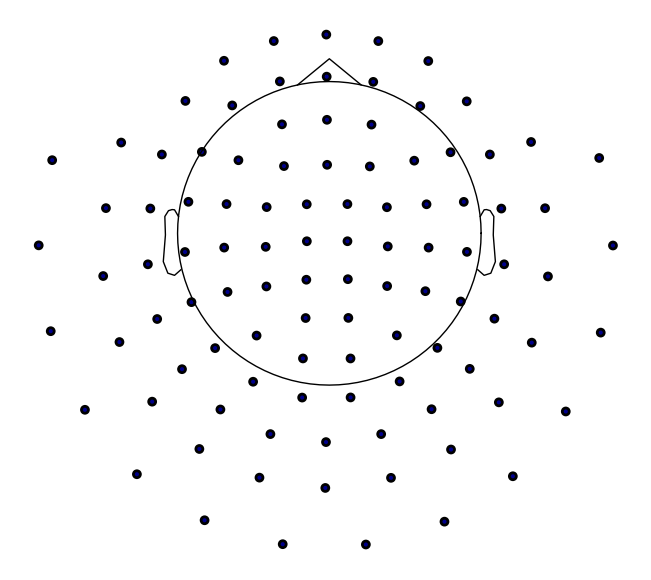

In [21]:
raw.plot_sensors(ch_type="mag");

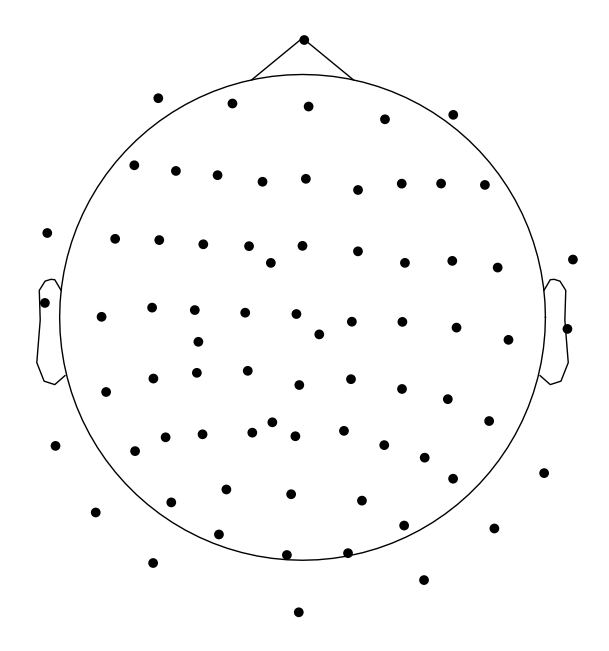

In [22]:
raw.plot_sensors(ch_type="eeg");

<div class="alert alert-success">
    <b>Exercise</b>:
     <ul>
    <li>Find out how to make <code>raw.plot_sensors()</code> show the names of the sensors as well.</li>
    </ul>
</div>

### Modifying channels

Some channels are wrongly defined as EEG in the file. 
Two of these are EOG (EEG061 and EEG062) and EEG063 is actually an ECG channel. EEG064 was recording but not connected to anything, so we'll make it `"misc"` instead. 
We will now set the channel types for those wrongly classified channels. This will be useful for automatic artifact rejection.

In [23]:
raw.set_channel_types?

Signature: raw.set_channel_types(mapping, *, on_unit_change='warn', verbose=None)
Docstring:
Specify the sensor types of channels.

Parameters
----------
mapping : dict
    A dictionary mapping channel names to sensor types, e.g.,
    ``{'EEG061': 'eog'}``.
on_unit_change : ``'raise'`` | ``'warn'`` | ``'ignore'``
    What to do if the measurement unit of a channel is changed
    automatically to match the new sensor type.

    .. versionadded:: 1.4

verbose : bool | str | int | None
    Control verbosity of the logging output. If ``None``, use the default
    verbosity level. See the :ref:`logging documentation <tut-logging>` and
    :func:`mne.verbose` for details. Should only be passed as a keyword
    argument.

Returns
-------
inst : same type as the input data
    The instance (modified in place).

    .. versionchanged:: 0.20
       Return the instance.

Notes
-----
The following :term:`sensor types` are accepted:

    bio, chpi, csd, dbs, dipole, ecg, ecog, eeg, emg, eog, exci,


In [24]:
raw.set_channel_types({"EEG061": "eog",  # actually EOG not EEG
                       "EEG062": "eog",  # actually EOG not EEG
                       "EEG063": "ecg",  # actually ECG not EEG
                       "EEG064": "misc"})  # EEG064 free-floating electrode

# we also rename the EOG and ECG channels:
raw.rename_channels({"EEG061": "EOG061",
                     "EEG062": "EOG062",
                     "EEG063": "ECG063"})
print(raw.info)

<Info | 23 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: []
 ch_names: MEG0113, MEG0112, MEG0111, MEG0122, MEG0123, MEG0121, MEG0132, ...
 chs: 204 Gradiometers, 102 Magnetometers, 70 EEG, 2 EOG, 1 ECG, 13 misc, 3 Stimulus
 custom_ref_applied: False
 description: (meg) Vectorview system at Cambridge
 dev_head_t: MEG device -> head transform
 dig: 287 items (3 Cardinal, 5 HPI, 75 EEG, 204 Extra)
 events: 1 item (list)
 experimenter: MEG
 file_id: 4 items (dict)
 highpass: 0.0 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 hpi_subsystem: 3 items (dict)
 line_freq: 50.0
 lowpass: 356.4 Hz
 meas_date: 1941-03-22 11:04:14 UTC
 meas_id: 4 items (dict)
 nchan: 395
 proj_id: 47
 proj_name: dgw_studies
 projs: mag_ssp_upright.fif : PCA-mags-v1: off, mag_ssp_upright.fif : ...
 sfreq: 1100.0 Hz
 subject_info: <subject_info | id: 813, birthday: 1978-01-01>
>


And let's remove unecessary channels - some empty stimulus channels, misc. channels, and HPI channels.

In [25]:
raw.drop_channels?

Signature: raw.drop_channels(ch_names, on_missing='raise')
Docstring:
Drop channel(s).

Parameters
----------
ch_names : iterable or str
    Iterable (e.g. list) of channel name(s) or channel name to remove.

on_missing : 'raise' | 'warn' | 'ignore'
    Can be ``'raise'`` (default) to raise an error, ``'warn'`` to emit a
    warning, or ``'ignore'`` to ignore when entries in ch_names are not present in the raw instance.

    .. versionadded:: 0.23.0

Returns
-------
inst : same type as the input data
    The modified instance.

See Also
--------
reorder_channels
pick_channels
pick_types

Notes
-----
.. versionadded:: 0.9.0
File:      ~/micromamba/lib/python3.13/site-packages/mne/channels/channels.py
Type:      method

In [26]:
to_drop = ["STI201", "STI301", "MISC201", "MISC202", "MISC203",
           "MISC204", "MISC205", "MISC206", "MISC301", "MISC302",
           "MISC303", "MISC304", "MISC305", "MISC306"]
raw.drop_channels(to_drop)

<Raw | sub-01_ses-meg_task-facerecognition_run-01_meg.fif, 381 x 540100 (491.0 s), ~6.9 MiB, data not loaded>

### Marking channels and segments as "BAD"

It's common during a recording that an electrode has a poor connection or a magnetometer is broken or ill-calibrated. We want to mark such channels as "bad" so MNE-Python will ignore them during the analysis. There are currently no channels marked as "bad". Let's take a look and see if we can spot some. In MNE-Python's raw browser, you can click on the timecourse of a channel to mark (or un-mark) the channel as "bad". After closing the window, the bad channels and segments will be stored in the `.info` dictionary.

In [27]:
raw.plot(lowpass=50)  # it can be userful to apply a frequency filter when looking at raw data

<mne_qt_browser._pg_figure.MNEQtBrowser(0x5c1d2069b010) at 0x7e1e9e646d00>

<div class="alert alert-success">
    <b>Exercise</b>:
     <ul>
    <li>There is one obviously bad EEG channels in this data. Find it and mark it as bad. You may find the zoom controls in the data browser useful: press the ? button in the toolbar to view all the hotkeys.</li>
    <li>There are other EEG channels we may consider marking as bad. Can you find some? What is it about them that make them "bad"?</li>
    </ul>
</div>


In [28]:
raw.info["bads"] = ["EEG064"]

In [29]:
print(raw.info["bads"])  # list of marked bad channels

['EEG064']


When entire segments of data are un-usable, for example because the participant was speaking or moving, you can annotate them in the raw browser:
1. Enter annotation-mode with the pencil button in the toolbar
2. Press "Add Description"
3. Enter "BAD_segment" as description
4. Click-and-drag with the mouse to select bad segments (right-click to un-mark)

### Accessing the data

By default, MNE-Python does not load all the raw data into memory at once (unless you specify `preload=True` during loading). We can access portions of the data using python's `[]` indexing syntax. Note that `raw[]` returns two things: the data and the times, both as [NumPy arrays](https://numpy.org/doc/stable/user/quickstart.html#the-basics).

In [30]:
start, stop = 0, 10
data, times = raw[:, start:stop]  # fetch all channels and the first 10 time points
print(data.shape)
print(times.shape)

(381, 10)
(10,)


In [31]:
times  # always starts at 0 by convention

array([0.        , 0.00090909, 0.00181818, 0.00272727, 0.00363636,
       0.00454545, 0.00545455, 0.00636364, 0.00727273, 0.00818182])

To load all the data into memory, we can use [`raw.load_data()`](https://mne.tools/stable/generated/mne.io.Raw.html#mne.io.Raw.load_data)

In [32]:
raw.load_data()
print(raw)

<Raw | sub-01_ses-meg_task-facerecognition_run-01_meg.fif, 381 x 540100 (491.0 s), ~1.54 GiB, data loaded>


Note that it now says: `data loaded`

### Maxfiltering the data

MNE-Python has its own implementation of the MegIn MaxFilter™ algorithm. For optimal effectiveness, we need to give it the calibration files of the MEG machine. This will take a while to run.

In [33]:
raw = mne.preprocessing.maxwell_filter(
    raw,
    calibration=f"{data_path}/meg_calibration/sss_cal.dat",
    cross_talk=f"{data_path}/meg_calibration/ct_sparse.fif",
    st_duration=60,  # perform tSSS
)

### Re-referencing EEG channels

With EEG it is common to record with a different reference than you want to use in the final analysis. MNE-Python objects have a [`.set_eeg_reference`](https://mne.tools/stable/generated/mne.io.Raw.html#mne.io.Raw.set_eeg_reference) method to set or change the EEG referencing scheme. Common setups are the average of two electrodes placed on the mastoids, or to the "common average reference", which is the average across all EEG channels:

In [34]:
# Re-reference the EEG to the average of two channels:
# raw.set_eeg_reference(ref_channels=["EEG040", "EEG050"])

# For source estimation later, we want a "common average reference", added as a projection.
raw.set_eeg_reference("average", projection=True)
print(raw.info["projs"])

[<Projection | Average EEG reference, active : False, n_channels : 70>]


### Resampling the data

We will now change the sampling frequency of the data to speed up the computations.

In [35]:
raw.resample(300)
print(raw.info)

<Info | 26 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 1 items (EEG064)
 ch_names: MEG0113, MEG0112, MEG0111, MEG0122, MEG0123, MEG0121, MEG0132, ...
 chs: 204 Gradiometers, 102 Magnetometers, 70 EEG, 2 EOG, 1 ECG, 1 misc, 1 Stimulus
 custom_ref_applied: False
 description: (meg) Vectorview system at Cambridge
 dev_head_t: MEG device -> head transform
 dig: 287 items (3 Cardinal, 5 HPI, 75 EEG, 204 Extra)
 events: 1 item (list)
 experimenter: MEG
 file_id: 4 items (dict)
 highpass: 0.0 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 hpi_subsystem: 3 items (dict)
 line_freq: 50.0
 lowpass: 150.0 Hz
 maxshield: False
 meas_date: 1941-03-22 11:04:14 UTC
 meas_id: 4 items (dict)
 nchan: 381
 proc_history: 1 item (list)
 proj_id: 47
 proj_name: dgw_studies
 projs: Average EEG reference: off
 sfreq: 300.0 Hz
 subject_info: <subject_info | id: 813, birthday: 1978-01-01>
>


### Frequency filtering

To see what effect filtering has for our data, let's quickly look at our data first! For full functionality, we ask matplotlib to show the plot in a separate window.

In [36]:
# Tell MNE-Python to use the fast QT data browser (should be the default)
raw.plot()

<mne_qt_browser._pg_figure.MNEQtBrowser(0x5c1d225a44e0) at 0x7e1eb72be340>

We are now going to plot the power spectrum. The PSD plot is interactive: select frequency bands to see its distribution scross sensors.

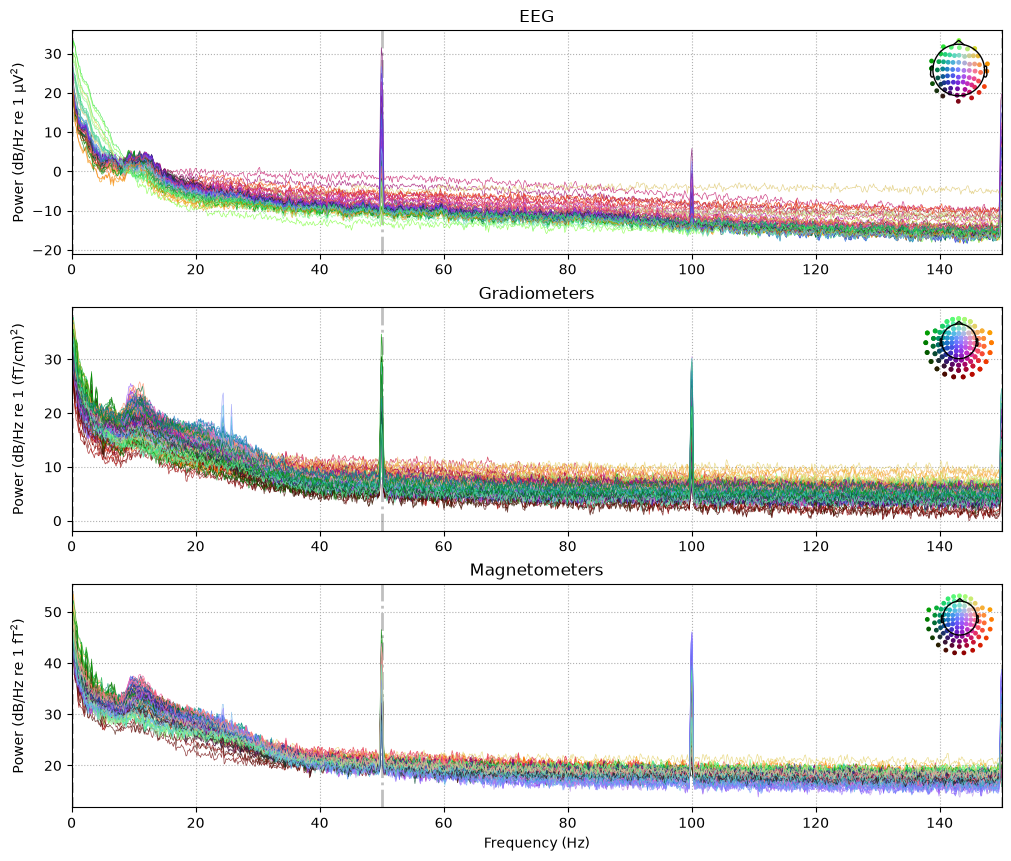

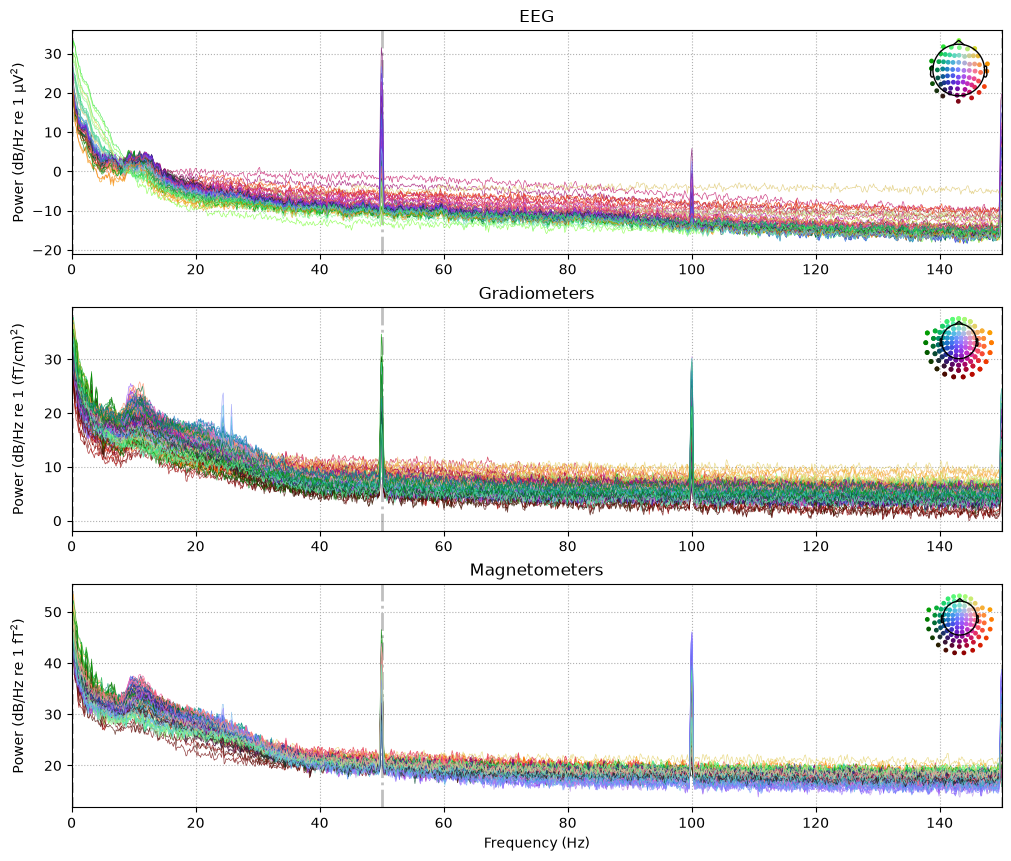

In [37]:
psd = raw.compute_psd()
psd.plot()

We want to filter the data between 0 and 40 Hz using a linear-phase finite-impulse response (FIR) filter.

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>Which parameters do we have to set to achieve this, based on the docstring of the [`raw.filter()`](https://mne.tools/stable/generated/mne.io.Raw.html#mne.io.Raw.filter) method?</li>
    </ul>
</div>


In [38]:
raw.filter?

Signature:
raw.filter(
    l_freq: float | None,
    h_freq: float | None,
    picks: str | numpy.ndarray | slice | None = None,
    filter_length: str | int = 'auto',
    l_trans_bandwidth: float | str = 'auto',
    h_trans_bandwidth: float | str = 'auto',
    n_jobs: int | str | None = None,
    method: str = 'fir',
    iir_params: dict | None = None,
    phase: str = 'zero',
    fir_window: str = 'hamming',
    fir_design: str = 'firwin',
    skip_by_annotation: str | list[str] | tuple[str, ...] = ('edge', 'bad_acq_skip'),
    pad: str = 'reflect_limited',
    verbose: bool | str | int | None = None,
) -> Self
Docstring:
Filter a subset of channels/vertices.

Parameters
----------

l_freq : float | None
    For FIR filters, the lower pass-band edge; for IIR filters, the lower
    cutoff frequency. If None the data are only low-passed.

h_freq : float | None
    For FIR filters, the upper pass-band edge; for IIR filters, the upper
    cutoff frequency. If None the data are only high-

In [39]:
raw.filter(0.05, 40)

<Raw | sub-01_ses-meg_task-facerecognition_run-01_meg.fif, 381 x 147300 (491.0 s), ~435.1 MiB, data loaded>

Now that we filtered our data, let's look at it again. Can you spot the difference?

In [40]:
raw.plot();

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>Which data changed more due to the filtering: EEG or MEG?</li>
      <li>Can you find reasons why?</li>
     </ul>
</div>

For more information on visualizing of raw data, see here: 
https://mne.tools/0.16/auto_tutorials/plot_visualize_raw.html


## Epochs

### The event structure of the data

The data has different events, which mark which stimulus was shown to the participants. The event/trigger structure is as follows:
- 5, 6, 7: famous faces
- 13, 14, 15: unfamiliar faces
- 17, 18, 19: scrambled faces

We first look at which events are there:

In [41]:
events = mne.find_events(raw, stim_channel='STI101', verbose=True)

Finding events on: STI101
259 events found on stim channel STI101
Event IDs: [   5    6    7   13   14   15   17   18   19  256  261  262  263  269
  270  271  273  274  275 4096 4101 4102 4103 4109 4110 4111 4113 4114
 4115 4352]


<div class="alert alert-success">
    <b>Exercise</b>:
     <ul>
    <li>What is the type of the variable events?</li>
    <li>What is the meaning of the 3 columns of events?</li>
    <li>How many events of the value 5 are there?
    </ul>
</div>

 

Let's visualize the paradigm:

In [42]:
events = events[events[:, 2] < 20]  # take only events with code less than 20

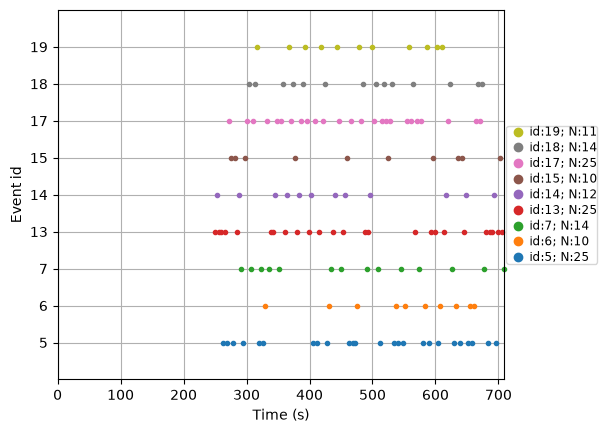

In [43]:
mne.viz.plot_events(events, raw.info["sfreq"]);

For event trigger and conditions we use a Python dictionary with keys that contain "/" for grouping sub-conditions

In [44]:
event_id = {
    "face/famous/first": 5,
    "face/famous/immediate": 6,
    "face/famous/long": 7,
    "face/unfamiliar/first": 13,
    "face/unfamiliar/immediate": 14,
    "face/unfamiliar/long": 15,
    "scrambled/first": 17,
    "scrambled/immediate": 18,
    "scrambled/long": 19,
}

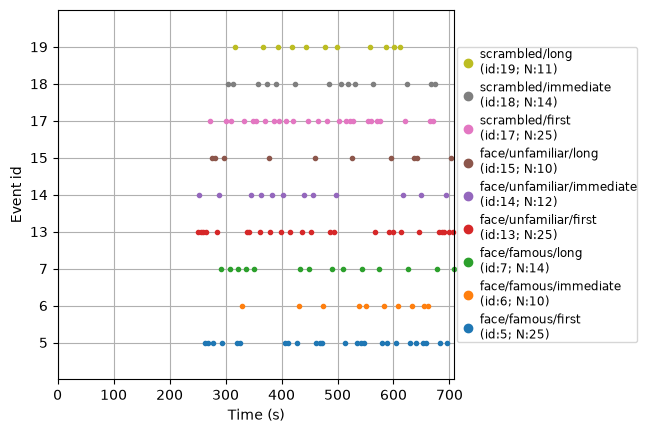

In [45]:
mne.viz.plot_events(events, sfreq=raw.info["sfreq"], event_id=event_id);

We can now re-visit our raw data plot:

In [46]:
raw.plot(event_id=event_id, events=events)

<mne_qt_browser._pg_figure.MNEQtBrowser(0x5c1d2ed31e70) at 0x7e1e6817b4c0>

### Cutting epochs

Define epochs parameters:

In [47]:
tmin = -0.5  # start of each epoch (500ms before the trigger)
tmax = 2.0  # end of each epoch (2000ms after the trigger)

Define the baseline period:

In [48]:
baseline = (-0.2, 0)  # means from 200ms before to stim onset (t = 0)

The easiest (and maybe also most dangerous?) way to clean your data is to define peak-to-peak (amplitude range) rejection parameters for gradiometers, magnetometers and EOG.

In [49]:
reject = dict(grad=4000e-13, mag=4e-12, eog=150e-6)  # this can be highly data dependent

Now we can put all of this together and create epochs:

In [50]:
epochs = mne.Epochs(raw, events, event_id, tmin, tmax, baseline=baseline, reject=reject)

In [51]:
print(epochs)  # let's look at some details about the epochs object

<Epochs | 146 events (good & bad), -0.5 – 2 s (baseline -0.2 – 0 s), ~7.0 MiB, data not loaded,
 'face/famous/first': 25
 'face/famous/immediate': 10
 'face/famous/long': 14
 'face/unfamiliar/first': 25
 'face/unfamiliar/immediate': 12
 'face/unfamiliar/long': 10
 'scrambled/first': 25
 'scrambled/immediate': 14
 'scrambled/long': 11>


Let's explicitly drop the epochs we identified as _bad_ through the thresholds we identified above:

In [52]:
epochs.drop_bad()  # remove bad epochs based on reject

<Epochs | 79 events (all good), -0.5 – 2 s (baseline -0.2 – 0 s), ~7.0 MiB, data not loaded,
 'face/famous/first': 13
 'face/famous/immediate': 3
 'face/famous/long': 6
 'face/unfamiliar/first': 17
 'face/unfamiliar/immediate': 4
 'face/unfamiliar/long': 6
 'scrambled/first': 15
 'scrambled/immediate': 9
 'scrambled/long': 6>

In [53]:
epochs.load_data()  # load data in memory

<Epochs | 79 events (all good), -0.5 – 2 s (baseline -0.2 – 0 s), ~179.4 MiB, data loaded,
 'face/famous/first': 13
 'face/famous/immediate': 3
 'face/famous/long': 6
 'face/unfamiliar/first': 17
 'face/unfamiliar/immediate': 4
 'face/unfamiliar/long': 6
 'scrambled/first': 15
 'scrambled/immediate': 9
 'scrambled/long': 6>

### Accounting for projector delay

During stimulus presentation, there was a delay of 34.5 ms between the event marker and the projector actually showing the image.
We need to correct the events accordingly.

In [54]:
epochs.shift_time(0.034)

<Epochs | 79 events (all good), -0.466 – 2.034 s (baseline -0.2 – 0 s), ~179.4 MiB, data loaded,
 'face/famous/first': 13
 'face/famous/immediate': 3
 'face/famous/long': 6
 'face/unfamiliar/first': 17
 'face/unfamiliar/immediate': 4
 'face/unfamiliar/long': 6
 'scrambled/first': 15
 'scrambled/immediate': 9
 'scrambled/long': 6>

## Artifact rejection through ICA

See how epochs were dropped

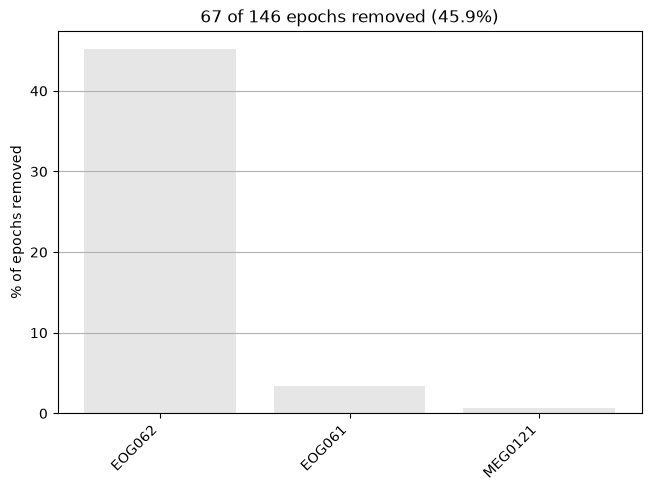

In [55]:
epochs.plot_drop_log();

### Wait a second, did we just loose half of our epochs due to EOG???

We can probably do better. Let's use indepandent component analysis (ICA) to remove components related to EOG and other offenders, ie., ECG.

Here is the workflow, we'll first detect EOG artifacts and visualize their impact. Then we'll use ICA to mitigate these artifacts.

In [56]:
# For this ICA part, we want to work on a copy of the data highpass filtered above 1 Hz.
raw_highpass = raw.copy().filter(1, None)

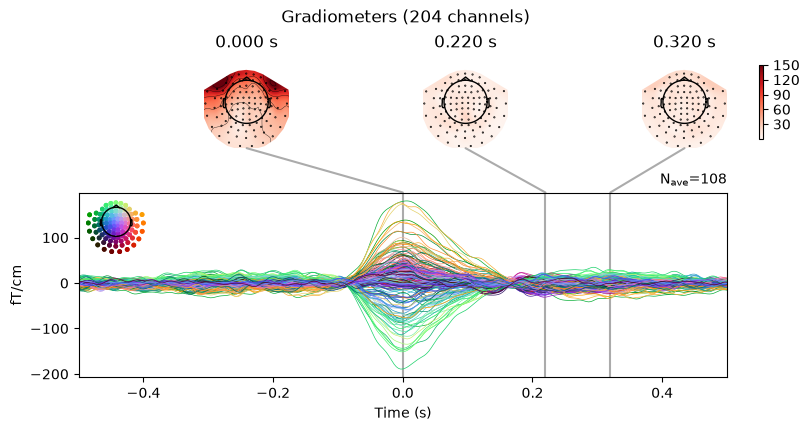

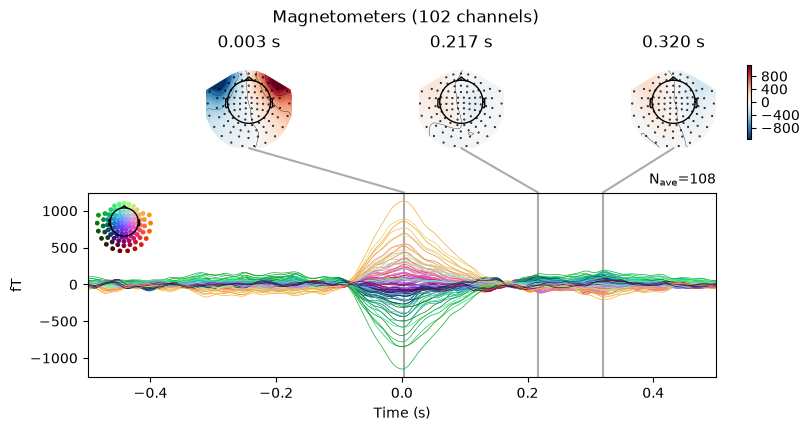

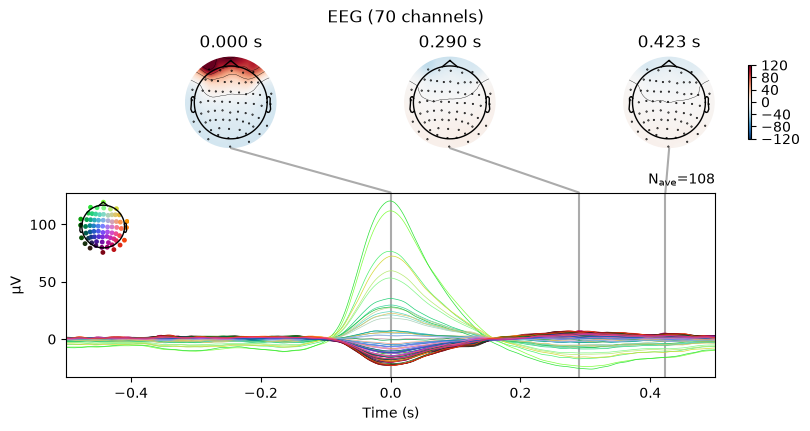

In [57]:
# There is a function to create EOG epochs:
eog_epochs = mne.preprocessing.create_eog_epochs(raw_highpass)
eog_epochs.average().plot_joint();

Let's see where those EOG segments show up in our raw data:

In [58]:
raw.plot(events=eog_epochs.events);

Let's perform ICA on the raw data. It needs data that is well-centered on 0, so we high-pass first.
To speed things up, only fit enough components to explain 95% of the data. The ICA algorithm is initialized using random numbers. Whenever you use random numbers in a data analysis pipeline, it is good practice to use a "seed". This way, every time you re-run a script, the exact same random numbers are generated. Use different seeds for different analys steps though!

In [59]:
ica = mne.preprocessing.ICA(0.95, random_state=68454).fit(raw_highpass)

The ICA algorithm has decomposed our signal into statistically independant "components". Each component is a linear mixture of the channels. Let's look at them:

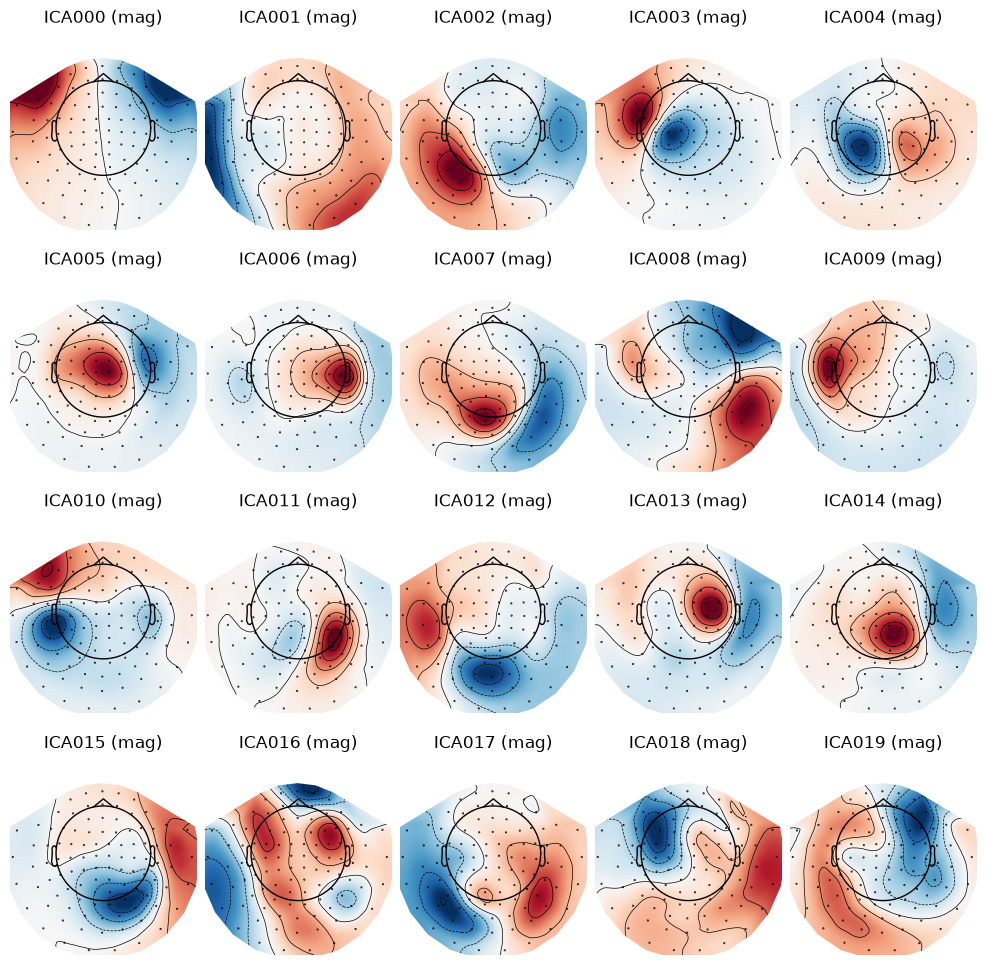

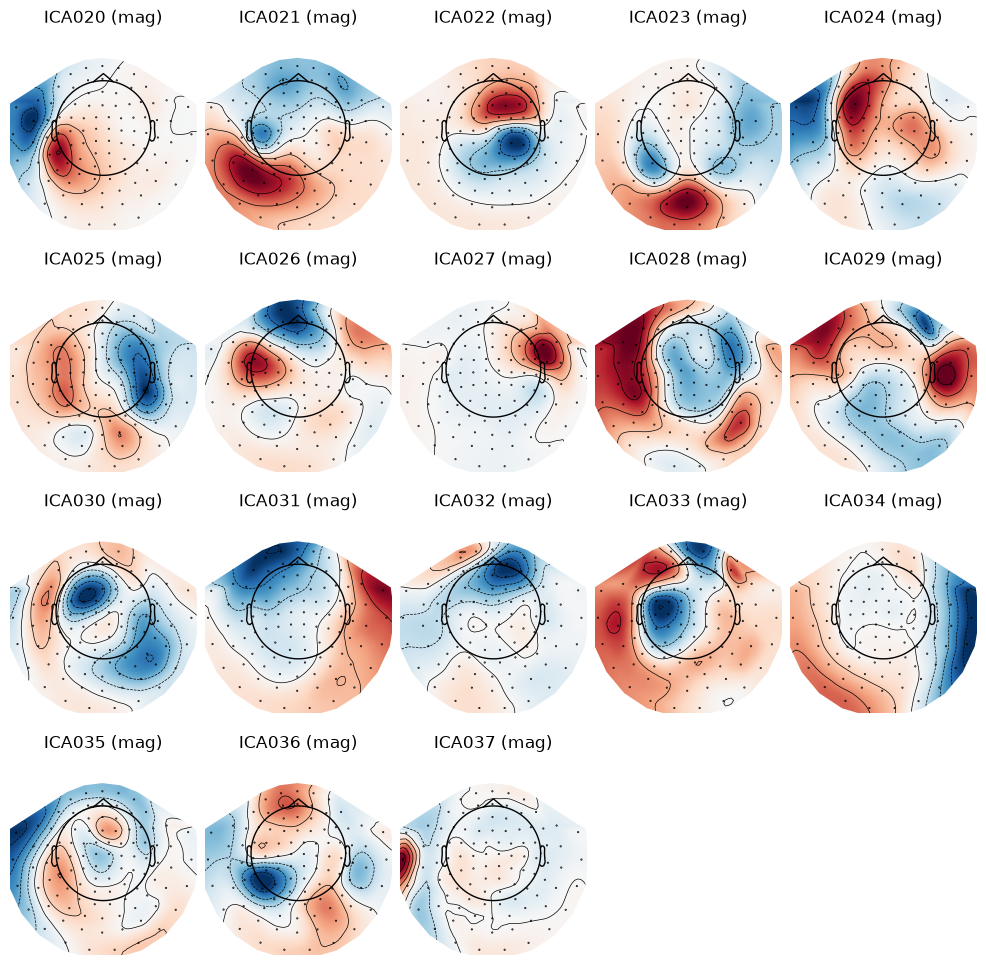

In [60]:
ica.plot_components();

Looking at the weights given to the channels, experienced analysts can readily spot likely components related to eye artifacts. Compare the topomaps in this figure with the ones we created for the `eog_epochs` above. In this case the first component (ICA000) is a dead ringer for capturing blinks. A good way to automatically flag come candidate components is to compute the correlation between the time course of the component and that of the EOG sensor.

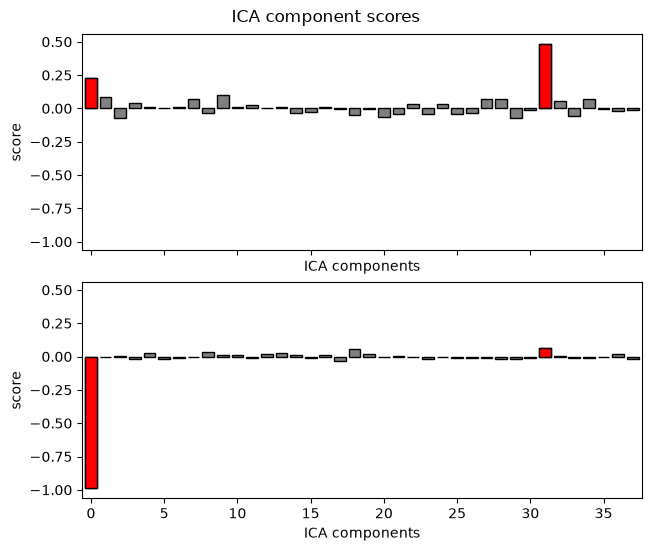

In [61]:
bads_eog, eog_scores = ica.find_bads_eog(raw_highpass)
ica.plot_scores(eog_scores, bads_eog);

This approach flagged two components with a strong correlation with the EOG sensor. Let's look at both of them in more detail:

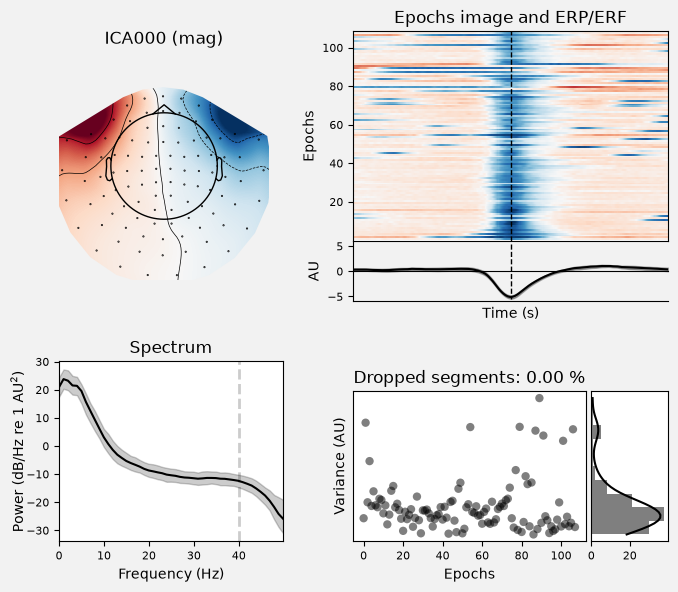

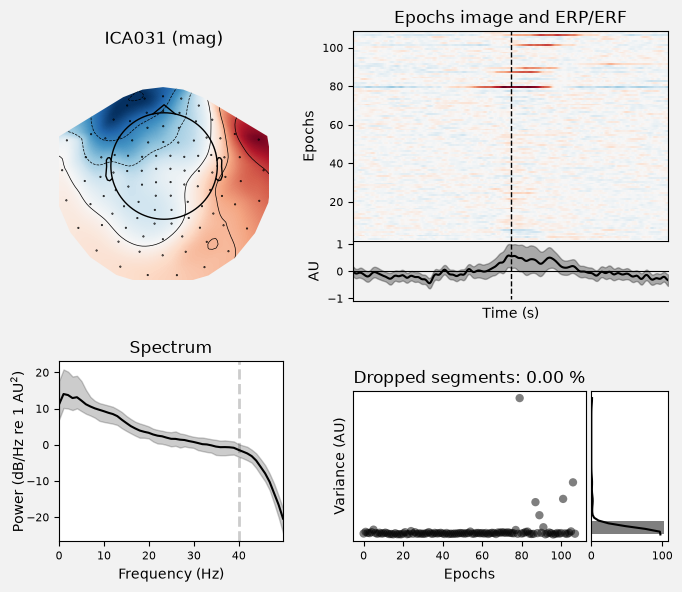

In [62]:
ica.plot_properties(eog_epochs, bads_eog);

These components indeed look like eye artifacts.

Another common source of artifacts is the heart. We can repeat the same procedure for ECG:

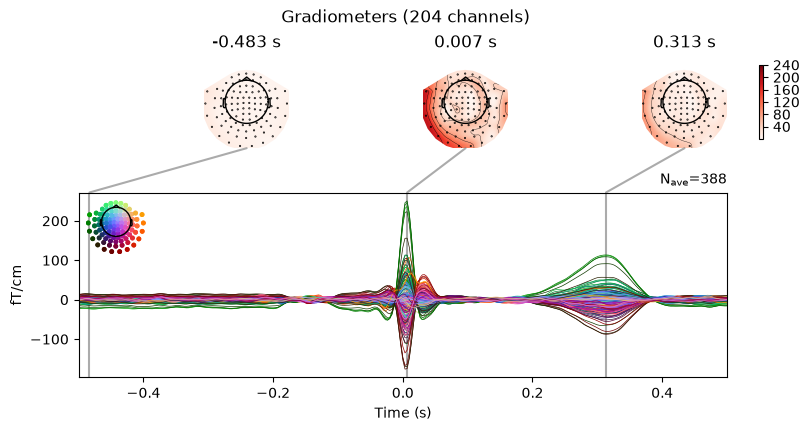

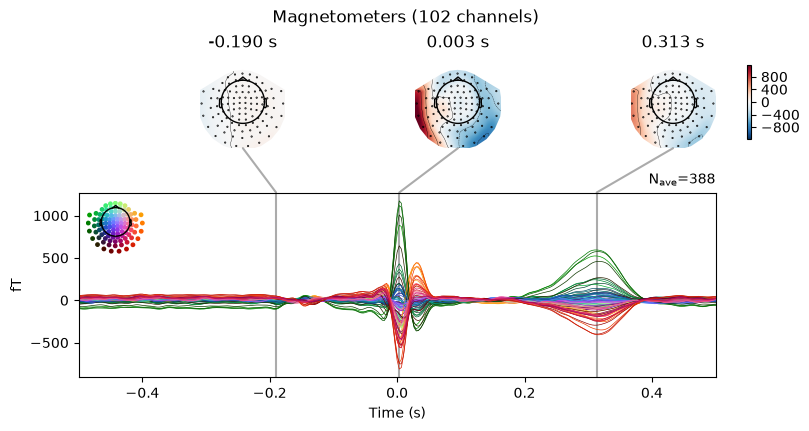

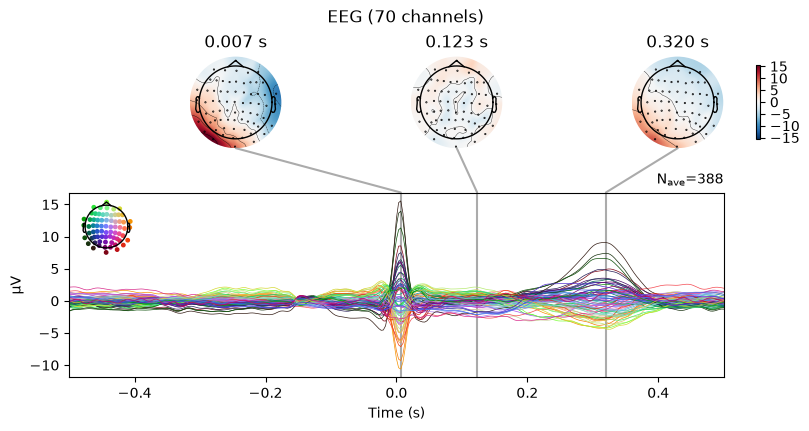

In [63]:
ecg_epochs = mne.preprocessing.create_ecg_epochs(raw_highpass)
ecg_epochs.average().plot_joint();

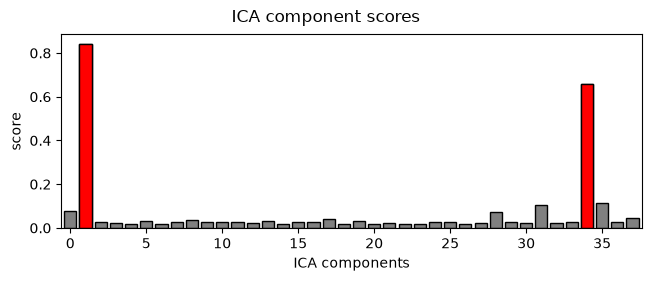

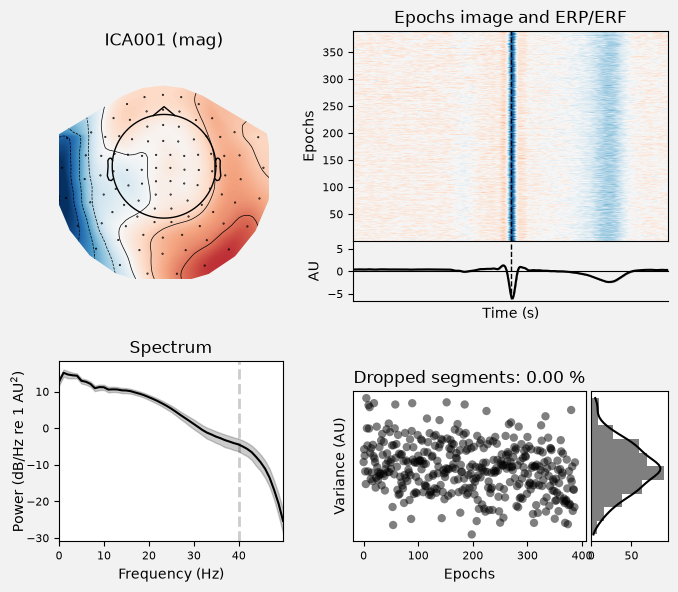

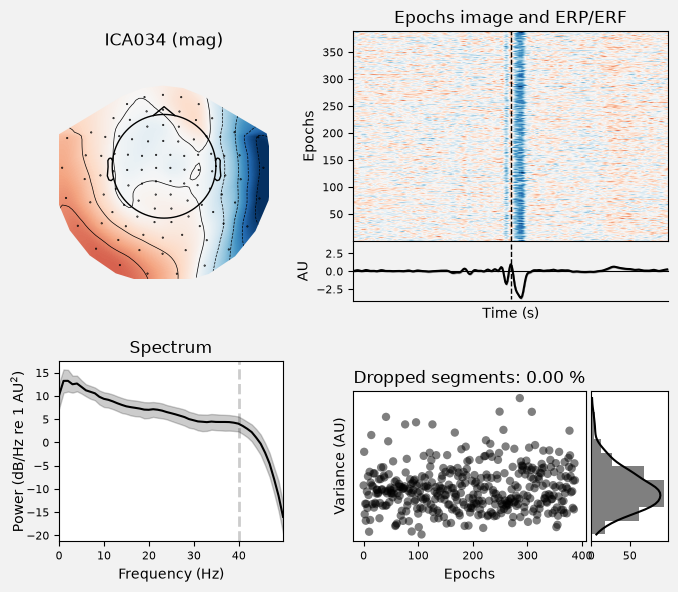

In [64]:
bads_ecg, ecg_scores = ica.find_bads_ecg(raw_highpass)
ica.plot_scores(ecg_scores, bads_ecg);
ica.plot_properties(ecg_epochs, bads_ecg, topomap_args=dict(sphere="eeg"));

We can see that we also face contamination from the cardiac signal... we'll project that out as well.

### Apply ICA and visualize effect

Let's mark the detected EOG and ECG components for removal and apply the ICA to the epoched data.

In [65]:
ica.exclude = bads_eog + bads_ecg

# Re-do the epochs without dropping them based on the EOG
epochs = mne.Epochs(raw, events, event_id, tmin, tmax, baseline=baseline, preload=True)

# Instead, clean them with the ICA.
epochs_clean = ica.apply(epochs.copy())
epochs_clean.apply_baseline()

<Epochs | 146 events (all good), -0.5 – 2 s (baseline -0.5 – 0 s), ~325.7 MiB, data loaded,
 'face/famous/first': 25
 'face/famous/immediate': 10
 'face/famous/long': 14
 'face/unfamiliar/first': 25
 'face/unfamiliar/immediate': 12
 'face/unfamiliar/long': 10
 'scrambled/first': 25
 'scrambled/immediate': 14
 'scrambled/long': 11>

Let's look at one frontal MEG channel before and after applying the ICA:

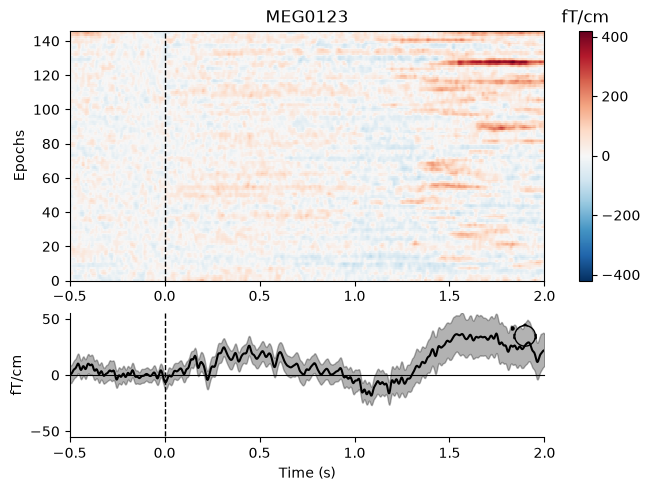

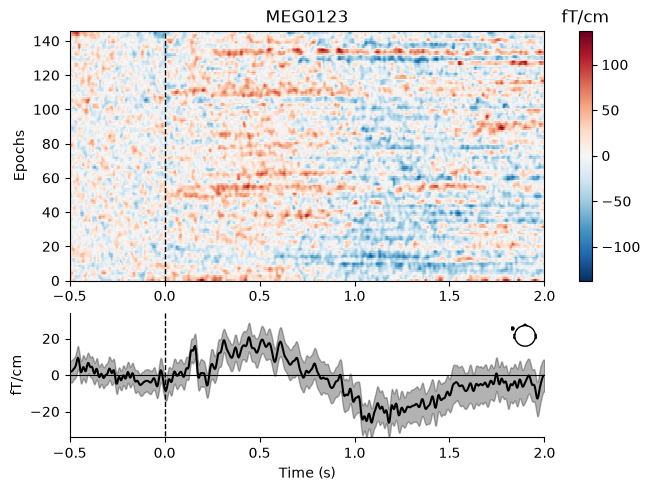

In [66]:
epochs.plot_image(picks='MEG0123', sigma=1.);
epochs_clean.plot_image(picks='MEG0123', sigma=1.);

#### Some thoughts on artifact rejection

We now tackled the artifacts in this data set through ICA. There are many other ways to do artifact rejection:

- mark artifacts by hand (visual inspection)
- use thresholds (which failed on this dataset!)
- use an automated pipeline, e.g. the <a href="https://autoreject.github.io/">autoreject project</a>

The best recommendation is: get to know your (raw) data!

## Saving data

Many MNE-Python objects have a `.save(filename)` method. Epochs are normally saved with the suffix `-epo.fif`. This saves them as a `.fif` file, together with all the metadata such as the `.info` dictionary.

In [67]:
# Make sure the folder for the processed data exists.
import os
os.makedirs(f"{processed_path}/sub-01", exist_ok=True)

# Save the epochs in the correct folder.
epochs_clean.save(f"{processed_path}/sub-01/sub-01_epo.fif", overwrite=True)

[PosixPath('/home/vanvlm1/projects/mne-course/data/processed/sub-01/sub-01_epo.fif')]

Let's also save the ICA model we fitted so we can inspect it later.

In [68]:
ica.save(f"{processed_path}/sub-01/sub-01_ica.fif", overwrite=True)

Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=1000
Fit,65 iterations on raw data (147300 samples)
ICA components,38
Available PCA components,376
Channel types,"mag, grad, eeg"
ICA components marked for exclusion,ICA000ICA031ICA001ICA034
